# Tuning decision-tree complexity with held-out AUC

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/evaluation/03-decision-tree-hyperparameter-tuning.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

A decision tree can become increasingly flexible: it can split more times and create smaller, more specialized regions of the feature space. That flexibility can uncover useful structure, but it can also memorize details that do not repeat in future turbine operation.

In this notebook, we predict the binary **positive/negative CO-emission label** using gas-turbine operating measurements. We use one fixed train/test split and ROC AUC to see how two tree hyperparameters control the tradeoff between fit and generalization.

## 1. Fix one train/test split

Each row in the dataset is one gas-turbine operating observation. The target `high_co` is a binary label; we offer the tree nine measured operating quantities but exclude `CO` itself, because that measurement defines the label.

We make one stratified 70/30 split. Stratification keeps the positive-label fraction similar in the training and test sets. We will keep this split fixed throughout the notebook so that a change in AUC can be attributed to a change in tree complexity.

Decision trees do not require feature standardization: a split such as `TIT < 1060` is unaffected by a linear rescaling of `TIT`.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
deep_palette = sns.color_palette("deep")
training_color, test_color = deep_palette[:2]

DATA_URL = (
    "https://raw.githubusercontent.com/changyaochen/MECE4520/master/"
    "site/data/gas-turbine-course.csv"
)
data_candidates = [
    Path("../data/gas-turbine-course.csv"),
    Path("site/data/gas-turbine-course.csv"),
    Path("gas-turbine-course.csv"),
]
data_path = next((path for path in data_candidates if path.exists()), data_candidates[-1])

# In Google Colab, download the small course dataset if it is not already present.
if not data_path.exists():
    urlretrieve(url=DATA_URL, filename=data_path)

FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
TARGET = "high_co"
RANDOM_STATE = 4520

data = pd.read_csv(filepath_or_buffer=data_path)
model_data = data[FEATURES + [TARGET]].dropna().copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_data[FEATURES],
    model_data[TARGET],
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=model_data[TARGET],
)

split_summary = pd.DataFrame(
    {
        "observations": [len(X_train), len(X_test)],
        "positive-label fraction": [y_train.mean(), y_test.mean()],
    },
    index=["Training set", "Test set"],
)
split_summary.style.format({"positive-label fraction": "{:.1%}"})

,observations,positive-label fraction
Training set,24778,38.8%
Test set,10620,38.8%


### ROC AUC as the score

A tree assigns each observation the positive-label fraction in the leaf where it lands. ROC AUC evaluates whether those leaf probabilities rank positive observations above negative ones, without fixing a single decision threshold. Higher AUC is better; 0.5 is the performance of an uninformative ranking.

The tree fitting algorithm chooses splits using Gini reduction, not AUC directly. Nevertheless, as a tree becomes more flexible, its **training AUC will usually rise or plateau**. The held-out test AUC is the quantity that tells us whether extra flexibility generalizes.

In [2]:
def fit_and_score_tree(
    *, max_depth: int | None, min_samples_leaf: int
) -> dict[str, float | int | None]:
    """Fit one classification tree and score it on the fixed split.

    Args:
        max_depth: Maximum number of split levels. Use ``None`` for no depth limit.
        min_samples_leaf: Smallest number of observations allowed in a terminal leaf.

    Returns:
        The tree settings, number of terminal leaves, and training/test ROC AUC.
    """
    tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=RANDOM_STATE,
    )
    tree.fit(X=X_train, y=y_train)

    training_probability = tree.predict_proba(X_train)[:, 1]
    test_probability = tree.predict_proba(X_test)[:, 1]

    return {
        "max depth": max_depth,
        "minimum leaf size": min_samples_leaf,
        "terminal leaves": tree.get_n_leaves(),
        "training AUC": roc_auc_score(y_train, training_probability),
        "test AUC": roc_auc_score(y_test, test_probability),
    }

## 2. First control knob: maximum tree depth

`max_depth` limits how many levels of rules the tree may create. A depth-1 tree has one split; each additional level can refine the operating regions further. We first hold the minimum leaf size at 1, then fit a sequence of increasingly deep trees.

The vertical line will mark the depth with the highest test AUC for this particular split. It is not a universal best depth: a different sample split can move the exact peak.

In [3]:
depths = list(range(1, 16))
depth_results = pd.DataFrame(
    [fit_and_score_tree(max_depth=depth, min_samples_leaf=1) for depth in depths]
)
best_depth = int(depth_results.loc[depth_results["test AUC"].idxmax(), "max depth"])

unrestricted_result = pd.DataFrame(
    [fit_and_score_tree(max_depth=None, min_samples_leaf=1)],
    index=["No depth limit"],
)

depth_results.round(3)

,max depth,minimum leaf size,terminal leaves,training AUC,test AUC
0,1,1,2,0.819,0.818
1,2,1,4,0.856,0.855
2,3,1,8,0.873,0.873
3,4,1,16,0.883,0.882
4,5,1,31,0.893,0.891
5,6,1,60,0.906,0.899
6,7,1,109,0.917,0.902
7,8,1,182,0.928,0.899
8,9,1,281,0.939,0.901
9,10,1,403,0.947,0.895


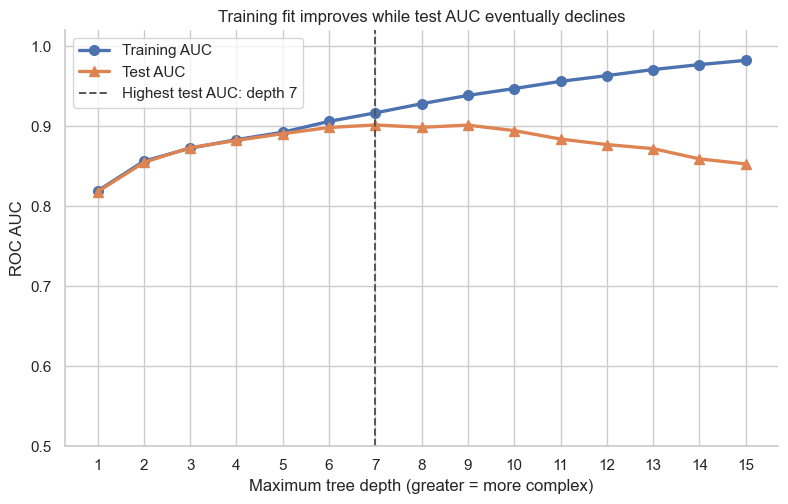

,terminal leaves,training AUC,test AUC
Depth 1,2,0.819,0.818
Depth 7,109,0.917,0.902
Depth 15,1198,0.982,0.853
No depth limit,2380,1.000,0.833


In [4]:
fig, axis = plt.subplots(figsize=(9.2, 5.4))
axis.plot(
    depth_results["max depth"],
    depth_results["training AUC"],
    marker="o",
    markersize=7,
    linewidth=2.4,
    color=training_color,
    label="Training AUC",
)
axis.plot(
    depth_results["max depth"],
    depth_results["test AUC"],
    marker="^",
    markersize=7,
    linewidth=2.4,
    color=test_color,
    label="Test AUC",
)
axis.axvline(
    best_depth,
    color="#555555",
    linestyle="--",
    linewidth=1.4,
    label=f"Highest test AUC: depth {best_depth}",
)
axis.set(
    title="Training fit improves while test AUC eventually declines",
    xlabel="Maximum tree depth (greater = more complex)",
    ylabel="ROC AUC",
    xticks=depths,
    ylim=(0.5, 1.02),
)
axis.legend(frameon=True)
sns.despine(ax=axis)
plt.show()

comparison_depths = [1, best_depth, 15]
depth_comparison = depth_results.set_index("max depth").loc[comparison_depths].copy()
depth_comparison.index = [f"Depth {depth}" for depth in comparison_depths]
unrestricted_comparison = unrestricted_result.assign(setting="No depth limit").set_index("setting")
comparison_columns = ["terminal leaves", "training AUC", "test AUC"]
pd.concat([depth_comparison, unrestricted_comparison])[comparison_columns].round(3)

## 3. Second control knob: minimum leaf size

A tree with `min_samples_leaf = 1` may create leaves containing only one operating observation. That makes the tree highly specialized. Increasing the minimum leaf size forces each terminal rule to summarize more observations, making the tree less flexible.

For this sweep, we remove the depth limit and vary only the minimum leaf size. The plot orders leaf sizes from large to small so that complexity increases from left to right.

In [5]:
leaf_sizes = [3000, 1000, 500, 200, 100, 50, 20, 10, 5, 1]
leaf_results = pd.DataFrame(
    [
        fit_and_score_tree(max_depth=None, min_samples_leaf=leaf_size)
        for leaf_size in leaf_sizes
    ]
)
best_leaf_size = int(
    leaf_results.loc[leaf_results["test AUC"].idxmax(), "minimum leaf size"]
)

leaf_results.round(3)

,max depth,minimum leaf size,terminal leaves,training AUC,test AUC
0,None,3000,7,0.879,0.878
1,None,1000,20,0.901,0.900
2,None,500,37,0.909,0.905
3,None,200,89,0.927,0.918
4,None,100,169,0.937,0.921
5,None,50,301,0.950,0.925
6,None,20,606,0.967,0.920
7,None,10,943,0.980,0.911
8,None,5,1407,0.990,0.893
9,None,1,2380,1.000,0.833


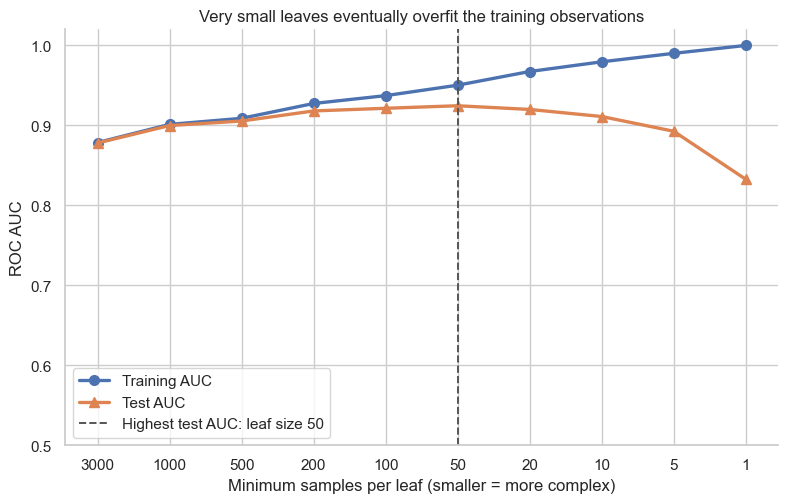

,terminal leaves,training AUC,test AUC
minimum leaf size,,,
3000,7,0.879,0.878
50,301,0.950,0.925
1,2380,1.000,0.833


In [6]:
positions = np.arange(len(leaf_results))
best_leaf_position = int(
    leaf_results.index[leaf_results["minimum leaf size"] == best_leaf_size][0]
)

fig, axis = plt.subplots(figsize=(9.2, 5.4))
axis.plot(
    positions,
    leaf_results["training AUC"],
    marker="o",
    markersize=7,
    linewidth=2.4,
    color=training_color,
    label="Training AUC",
)
axis.plot(
    positions,
    leaf_results["test AUC"],
    marker="^",
    markersize=7,
    linewidth=2.4,
    color=test_color,
    label="Test AUC",
)
axis.axvline(
    best_leaf_position,
    color="#555555",
    linestyle="--",
    linewidth=1.4,
    label=f"Highest test AUC: leaf size {best_leaf_size}",
)
axis.set(
    title="Very small leaves eventually overfit the training observations",
    xlabel="Minimum samples per leaf (smaller = more complex)",
    ylabel="ROC AUC",
    xticks=positions,
    xticklabels=leaf_results["minimum leaf size"].astype(str),
    ylim=(0.5, 1.02),
)
axis.legend(frameon=True)
sns.despine(ax=axis)
plt.show()

comparison_leaf_sizes = [3000, best_leaf_size, 1]
leaf_comparison = leaf_results.set_index("minimum leaf size").loc[comparison_leaf_sizes]
leaf_comparison[["terminal leaves", "training AUC", "test AUC"]].round(3)

## 4. What did held-out AUC tell us?

Both hyperparameters control the same broad idea—**tree complexity**—but they do so differently:

- `max_depth` caps how many sequential rules the tree may use.
- `min_samples_leaf` prevents the tree from creating tiny, highly specialized leaves.

In both sweeps, the training AUC keeps improving as we allow greater complexity. The held-out test AUC first improves because the model captures more real structure, then falls when the tree starts fitting split-specific details. With AUC on the vertical axis, that is an **inverted-U** pattern; if we plotted error as $1 - \mathrm{AUC}$, it would be the familiar U-shaped curve.

The two sweeps are not an exhaustive joint search: each one holds the other hyperparameter fixed. Their purpose is to establish a practical rule: choose hyperparameters using held-out performance, not the best training score.

## Takeaways

- A fully grown decision tree can memorize the training set, producing a training AUC of 1.0 without necessarily generalizing well.
- Tree depth and minimum leaf size are **hyperparameters**: choices made before fitting the tree.
- More flexible trees can improve test performance at first, but excessive complexity can lower held-out AUC.
- For a fixed train/test split, compare candidate settings with the same held-out metric. A different split can shift the exact best setting.

## Try it

Change one candidate depth or minimum leaf size, fit its tree, and compare its training and test AUC with the curves above.

[← Return to Evaluation](index.qmd)

In [7]:
# Try a different depth.
# my_depth_result = fit_and_score_tree(max_depth=9, min_samples_leaf=1)
# pd.DataFrame([my_depth_result]).round(3)

# Try a different minimum leaf size.
# my_leaf_result = fit_and_score_tree(max_depth=None, min_samples_leaf=75)
# pd.DataFrame([my_leaf_result]).round(3)